# 07a Classical forecasting

This is where we start forecasting. We fit the classical time-series models one after another, from the simplest
to the most involved: seasonal naive (next week = last week), exponential smoothing (ETS and Holt-Winters), ARIMA
and SARIMA, and TSB for the few products that sell only now and then. Each one is tested the same way, on a rolling
backtest that only ever lets a model see the past. The scores here are what machine learning has to beat in 09.

## The backtest

We make forecasts from 7 dates ("origins"), 28 days apart, each forecasting the next 28 days: 2015-11-08,
2015-12-06, 2016-01-03, 2016-01-31, 2016-02-28, 2016-03-27 and 2016-04-24. The first is a warm-up: its errors are
used later to size uncertainty bands and safety stock, but it is not scored. Origins 1 to 6 are scored, so the test
days run from 7 December 2015 to 22 May 2016. At every origin a model is fitted again on data up to that date only,
and anything chosen about the model (like an ARIMA order) is chosen on the training data, never on the test days.

Seasonal naive, ETS and TSB are cheap, so we run them on all 726 products. Holt-Winters, ARIMA and SARIMA need an
order search and take about 40 minutes for 150 products on our laptop, so they run on a sample of 150, and all
the classical models are compared on that same sample. Both slow steps save their results, so running the notebook
again only takes a minute; set `RERUN = True` to fit everything from scratch.

## Load

In [1]:
import os, sys, json, time, warnings
sys.path.append("../src")
os.environ["PYTHONPATH"] = os.path.abspath("../src")    # the joblib workers need src/ too
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from config import (ROOT, INTERIM, PROCESSED, TABLES, FIGS, CHECKPOINTS, SEED, CATEGORIES, ORIGINS, EVAL_ORIGINS,
                    HORIZON, SAMPLE_PER_GROUP, FIG_STYLE, COLORS, NAMES)
import classical
from break_detection import to_weekly, surrogate_max_stats
from forecasting import training_windows, local_forecasts, is_intermittent
from metrics import all_errors, mase_scale
from evaluation import METRICS, mase_scales, score, summarise, paired_family

RERUN = False
N_JOBS = 10
BURN_IN, REF_LEN, K = 8, 52, 1.0
plt.rcParams.update(FIG_STYLE)
for p in [TABLES, FIGS, CHECKPOINTS / "items"]:
    p.mkdir(parents=True, exist_ok=True)
written = []

long_df = pd.concat([pd.read_csv(INTERIM / f"{c}_candidates.csv", parse_dates=["date"])
                     for c in ["foods", "hobbies", "household"]], ignore_index=True)
long_df = long_df.sort_values(["item_id", "date"]).reset_index(drop=True)
long_df["category"] = long_df["item_id"].str.split("_").str[0]
item_cat = long_df.groupby("item_id")["category"].first()
daily = {item: g[["date", "sales"]].reset_index(drop=True) for item, g in long_df.groupby("item_id")}
print(f"{len(daily)} products; origins:", [o.date() for o in ORIGINS])

726 products; origins: [datetime.date(2015, 11, 8), datetime.date(2015, 12, 6), datetime.date(2016, 1, 3), datetime.date(2016, 1, 31), datetime.date(2016, 2, 28), datetime.date(2016, 3, 27), datetime.date(2016, 4, 24)]


## Which products had a shift by each origin

To pick a fair sample we want half of it to be products whose level shifted at some point. The detector itself is
explained in `08a_break_detection`; here we only run it, at each origin, on the weeks up to that origin. Its
threshold is set on data before the first origin, so nothing leaks from the test period. The same table is what the
shift-aware models in 08d and 09b use.

In [2]:
path = PROCESSED / "breaks_by_origin.csv"
if RERUN or not path.exists():
    weekly_pre = {item: to_weekly(d[d["date"] <= ORIGINS[0]]).to_numpy() for item, d in daily.items()}
    H = float(np.quantile(surrogate_max_stats(weekly_pre, BURN_IN, REF_LEN, k=K, seed=SEED), 0.95))
    print(f"detector threshold from data before the first origin: {H:.2f}")
    windows = training_windows(daily, ORIGINS, H, k=K, burn_in=BURN_IN, ref_len=REF_LEN, seed=SEED)
    windows["category"] = windows["item_id"].map(item_cat)
    windows.to_csv(path, index=False)
windows = pd.read_csv(path, parse_dates=["origin", "first_date", "last_change_week", "last_alarm_week", "adaptive_start", "placebo_start"])
written.append(path)
print(windows.groupby("origin")["has_break"].mean().rename("share with a shift before the origin").round(3).to_string())

detector threshold from data before the first origin: 13.83


origin
2015-11-08    0.635
2015-12-06    0.640
2016-01-03    0.650
2016-01-31    0.657
2016-02-28    0.665
2016-03-27    0.667
2016-04-24    0.672


## The sample of 150

Per category, 25 products with a shift at some scored origin and 25 without, drawn with seed 42.

In [3]:
has_break = windows[windows["origin"].isin(EVAL_ORIGINS)].groupby("item_id")["has_break"].any()
sample = classical.draw_sample(has_break, CATEGORIES, SAMPLE_PER_GROUP, SEED)
sample.to_csv(TABLES / "classical_sample_items.csv", index=False)
written.append(TABLES / "classical_sample_items.csv")
sample.groupby(["category", "break_item"]).size().unstack()

break_item,False,True
category,,
FOODS,25,25
HOBBIES,25,25
HOUSEHOLD,25,25


## Seasonal naive, ETS and TSB on all 726 products

Seasonal naive repeats the last week. ETS here is Holt-Winters with an additive trend that is damped (it flattens
out over the 28 days, so a short-term trend is not run forward too far) and an additive weekly season, fitted by
statsmodels. TSB is meant for intermittent demand: it smooths how often a product sells and how much, separately.
We only use it for the 26 products that go more than 1.32 days between sales on average (the usual cut-off).

In [4]:
path = PROCESSED / "local_static_forecasts.parquet"
intermittent = {item: is_intermittent(d.loc[d["date"] <= ORIGINS[0], "sales"]) for item, d in daily.items()}
print("intermittent products (TSB):", sum(intermittent.values()))
if RERUN or not path.exists():
    t0 = time.time()
    starts = {item: {o: {"static": None} for o in ORIGINS} for item in daily}
    res = Parallel(n_jobs=-1, batch_size=4)(
        delayed(local_forecasts)(item, d["date"], d["sales"], ORIGINS, starts[item], run_tsb=intermittent[item])
        for item, d in daily.items())
    pd.DataFrame([r for rows in res for r in rows]).to_parquet(path, index=False)
    print(f"fitted in {(time.time() - t0) / 60:.1f} min")
local = pd.read_parquet(path)
written.append(path)
print(f"{len(local):,} forecast rows:", local["model"].value_counts().to_dict())

intermittent products (TSB): 26


fitted in 14.9 min
289,688 forecast rows: {'seasonal_naive': 142296, 'ets': 142296, 'tsb': 5096}


In [5]:
# score them on all 726 products
local = local.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
scales = mase_scales(daily, ORIGINS)
s726 = score(local, scales)
s726 = s726[s726["origin"].isin(EVAL_ORIGINS)].groupby(["item_id", "model"], as_index=False)[METRICS].mean()
s726["category"] = s726["item_id"].map(item_cat)
s726["intermittent"] = s726["item_id"].map(intermittent)
t726 = s726[s726["model"] != "tsb"].pivot_table(index="category", columns="model", values="mase", aggfunc="median")
t726.loc["ALL"] = s726[s726["model"] != "tsb"].groupby("model")["mase"].median()
print("median MASE over the 726 products:")
print(t726.round(3).to_string())
print("\nthe 26 intermittent products only:")
print(s726[s726["intermittent"]].groupby("model")["mase"].median().round(3).to_string())
s726.to_csv(TABLES / "classical_726_scores.csv", index=False)
written.append(TABLES / "classical_726_scores.csv")

median MASE over the 726 products:
model        ets  seasonal_naive
category                        
FOODS      0.771           0.957
HOBBIES    0.755           1.004
HOUSEHOLD  0.744           0.978
ALL        0.755           0.976

the 26 intermittent products only:
model
ets               0.962
seasonal_naive    1.147
tsb               0.986


## Holt-Winters, ARIMA and SARIMA on the sample

At each origin every model is fitted on the last 730 days: two full years, so the yearly pattern is seen twice,
while the fits stay quick and stable. The ARIMA and SARIMA orders are chosen once, on the data up to the warm-up
origin: d from a KPSS test (`ndiffs`), D from an OCSB test (`nsdiffs`, period 7), then every p, q in 0-2 and
P, Q in 0-1 is fitted and the lowest AICc wins. The order then stays fixed and the parameters are re-estimated at
every origin. If a fit crashes or returns nonsense (not a finite number), that forecast falls back to seasonal
naive, and we count how often that happens.

We also fit Holt-Winters without damping, with both an additive and a multiplicative weekly season, and the four
totals (three categories and California) with a wider order grid.

In [6]:
ck = CHECKPOINTS / "items"
series = {i: g.sort_values("date") for i, g in long_df[long_df["item_id"].isin(sample["item_id"])].groupby("item_id")}
todo = [i for i in sample["item_id"] if RERUN or not (ck / f"{i}.parquet").exists()]
print(f"{len(todo)} of {len(sample)} products to fit")
Parallel(n_jobs=N_JOBS, batch_size=1)(
    delayed(classical.run_item_to_file)(i, series[i]["date"], series[i]["sales"], ORIGINS, ck / f"{i}.parquet")
    for i in todo)

totals = {cat: long_df[long_df["category"] == cat].groupby("date")["sales"].sum() for cat in CATEGORIES}
totals["CA_TOTAL"] = long_df.groupby("date")["sales"].sum()

def run_total(name, s):
    return classical.run_item_to_file(name, s.index, s.to_numpy(), ORIGINS, ck / f"_agg_{name}.parquet", pq=range(4), PQ=range(3))

Parallel(n_jobs=4)(delayed(run_total)(k, v) for k, v in totals.items()
                   if RERUN or not (ck / f"_agg_{k}.parquet").exists())

0 of 150 products to fit


[]

In [7]:
def read_ck(name):
    df = pd.read_parquet(ck / f"{name}.parquet").assign(item_id=name)   # totals are labelled _agg_<name>
    orders = json.loads((ck / f"{name}.json").read_text())
    return df, orders

parts, order_rows = [], []
for name in list(sample["item_id"]) + [f"_agg_{k}" for k in totals]:
    df, o = read_ck(name)
    parts.append(df)
    order_rows.append({"series": name.replace("_agg_", ""), "level": "aggregate" if name.startswith("_agg_") else "item",
                       "d": o["d"], "D": o["D"], "sarima_order": tuple(o["sarima_order"]),
                       "sarima_sorder": tuple(o["sarima_sorder"]), "sarima_aicc": o["sarima_aicc"],
                       "arima_order": tuple(o["arima_order"]), "arima_aicc": o["arima_aicc"],
                       "grid_failed": o["sarima_grid_failed"] or o["arima_grid_failed"]})
new_fc = pd.concat(parts, ignore_index=True)
new_fc["series"] = new_fc["item_id"]
orders = pd.DataFrame(order_rows)
orders.to_csv(TABLES / "classical_orders.csv", index=False)
written.append(TABLES / "classical_orders.csv")
print(f"{len(new_fc):,} forecast rows from the slower models")

120,736 forecast rows from the slower models


## Scores on the sample

In [8]:
fast = local[local["item_id"].isin(sample["item_id"]) & local["model"].isin(["seasonal_naive", "ets"])]
fc = pd.concat([new_fc[~new_fc["item_id"].str.startswith("_agg_")][["item_id", "origin", "date", "model", "forecast"]],
                fast[["item_id", "origin", "date", "model", "forecast"]]], ignore_index=True)
fc = fc.merge(long_df[["item_id", "date", "sales"]].rename(columns={"sales": "actual"}), on=["item_id", "date"])
fc = fc.merge(sample[["item_id", "category"]], on="item_id")
fc.to_parquet(TABLES / "classical_forecasts.parquet", index=False)
written.append(TABLES / "classical_forecasts.parquet")

m = score(fc, scales).merge(sample, on="item_id")
m.to_csv(TABLES / "classical_metrics_item_origin.csv", index=False)
written.append(TABLES / "classical_metrics_item_origin.csv")

ORDER = ["seasonal_naive", "ets", "hw_add", "hw_mul", "arima", "sarima"]
ev = m[m["origin"].isin(EVAL_ORIGINS)]
per_item = ev.groupby(["item_id", "category", "break_item", "model"], as_index=False)[METRICS + ["mape_excluded"]].mean()
summary = summarise(per_item, ORDER, CATEGORIES)
summary.to_csv(TABLES / "classical_metrics_summary.csv", index=False)
written.append(TABLES / "classical_metrics_summary.csv")
show = summary[summary["category"] == "ALL"].set_index("model").loc[ORDER]
print(show[[f"median_{k}" for k in METRICS]].round(3).to_string())
print(f"\nMAPE leaves out {show['mape_excluded_share'].iloc[0]:.1%} of days, because nothing sold on them.")
print("\nmedian MASE by category:")
print(summary.pivot(index="model", columns="category", values="median_mase").loc[ORDER, ["ALL"] + CATEGORIES].round(3).to_string())

                median_rmse  median_mae  median_mape  median_smape  median_wape  median_mase
model                                                                                       
seasonal_naive        6.039       4.720        0.753         0.616        0.581        0.973
ets                   4.498       3.511        0.595         0.471        0.437        0.756
hw_add                4.560       3.560        0.595         0.480        0.442        0.757
hw_mul                4.554       3.586        0.595         0.482        0.439        0.761
arima                 4.822       3.775        0.638         0.484        0.458        0.794
sarima                4.445       3.522        0.603         0.474        0.435        0.755

MAPE leaves out 5.4% of days, because nothing sold on them.

median MASE by category:
category          ALL  FOODS  HOBBIES  HOUSEHOLD
model                                           
seasonal_naive  0.973  0.931    0.978      0.971
ets             0.756 

## Do they beat the baseline?

Paired Wilcoxon tests on each product's MASE, SARIMA and Holt-Winters against seasonal naive, Holm-corrected for the two tests.

In [9]:
wide = per_item.pivot(index="item_id", columns="model", values="mase")
h1 = pd.DataFrame(paired_family(wide, [("sarima", "seasonal_naive"), ("hw_add", "seasonal_naive")], "H1", seed=SEED))
h1[["model_a", "model_b", "n", "median_diff", "ci_low", "ci_high", "share_improved", "p_holm", "a_better"]].round(4)

,model_a,model_b,n,median_diff,ci_low,ci_high,share_improved,p_holm,a_better
0,sarima,seasonal_naive,150,-0.2234,-0.2370,-0.2000,0.9733,0.0,True
1,hw_add,seasonal_naive,150,-0.2184,-0.2328,-0.2071,0.9667,0.0,True


## Additive or multiplicative Holt-Winters?

We split the sample by how often a product sells nothing (above or below the sample median before the first
origin), because the multiplicative form needs the +1 trick on zero days. On the totals we fit both forms directly.

In [10]:
pre = long_df[long_df["item_id"].isin(sample["item_id"]) & (long_df["date"] <= ORIGINS[0])]
zero_share = pre.groupby("item_id")["sales"].apply(lambda s: (s == 0).mean())
cut = zero_share.median()
fb = new_fc[(new_fc["model"] == "hw_mul") & new_fc["origin"].isin(EVAL_ORIGINS) & ~new_fc["item_id"].str.startswith("_agg_")]
fb = fb.groupby("item_id")["fallback"].any()
h4 = []
for label, ids in [("zero-heavy", zero_share[zero_share > cut].index), ("not zero-heavy", zero_share[zero_share <= cut].index),
                   ("all", zero_share.index)]:
    x = wide.loc[ids]
    h4.append({"group": label, "n_items": len(ids), "zero_share_median": zero_share.loc[ids].median(),
               "median_mase_hw_add": x["hw_add"].median(), "median_mase_hw_mul": x["hw_mul"].median(),
               "share_items_add_better": (x["hw_add"] < x["hw_mul"]).mean(), "items_mul_fell_back": int(fb.loc[ids].sum())})
h4 = pd.DataFrame(h4)
print(f"zero-share cut (sample median): {cut:.3f}")

agg_rows = []
bottom_up = local[local["model"].isin(["seasonal_naive", "ets"])].copy()
bottom_up["category"] = bottom_up["item_id"].map(item_cat)
for name, s in totals.items():
    mine = new_fc[new_fc["item_id"] == f"_agg_{name}"]
    bu = bottom_up if name == "CA_TOTAL" else bottom_up[bottom_up["category"] == name]
    bu = bu.groupby(["origin", "date", "model"], as_index=False)["forecast"].sum()
    for (origin, model), g in pd.concat([mine[["origin", "date", "model", "forecast"]], bu]).groupby(["origin", "model"]):
        if origin not in EVAL_ORIGINS:
            continue
        act = s.reindex(g["date"]).to_numpy()
        sc = mase_scale(s[s.index <= origin].to_numpy())
        agg_rows.append({"series": name, "origin": origin, "model": model,
                         "how": "fitted on total" if model in ["hw_add", "hw_mul", "arima", "sarima"] else "sum of items",
                         **all_errors(act, g["forecast"], sc)})
agg = pd.DataFrame(agg_rows).groupby(["series", "model", "how"], as_index=False)[METRICS].mean()
h4b = agg.pivot(index="series", columns="model", values="mase")
h4b["mul_vs_add"] = h4b["hw_mul"] / h4b["hw_add"] - 1
h4b["mul_within_5pct"] = h4b["mul_vs_add"] <= 0.05
h4 = pd.concat([h4, h4b.reset_index()[["series", "hw_add", "hw_mul", "mul_vs_add", "mul_within_5pct"]]
                .rename(columns={"series": "group", "hw_add": "median_mase_hw_add", "hw_mul": "median_mase_hw_mul"})
                .assign(n_items=1)], ignore_index=True)
h4.to_csv(TABLES / "classical_h4.csv", index=False)
written.append(TABLES / "classical_h4.csv")
print(h4.round(4).to_string(index=False))

zero-share cut (sample median): 0.062


         group  n_items  zero_share_median  median_mase_hw_add  median_mase_hw_mul  share_items_add_better  items_mul_fell_back  mul_vs_add mul_within_5pct
    zero-heavy       74             0.1272              0.7626              0.7618                  0.5270                  0.0         NaN             NaN
not zero-heavy       76             0.0212              0.7540              0.7615                  0.5395                  0.0         NaN             NaN
           all      150             0.0625              0.7566              0.7615                  0.5333                  0.0         NaN             NaN
      CA_TOTAL        1                NaN              0.7905              0.7698                     NaN                  NaN     -0.0262            True
         FOODS        1                NaN              0.8494              0.8521                     NaN                  NaN      0.0032            True
       HOBBIES        1                NaN              0.6608  

## The totals

Classical models fitted on each total, against seasonal naive and ETS added up from the 726 product forecasts.

In [11]:
print(agg.pivot(index="model", columns="series", values="mase").loc[ORDER].round(3).to_string())

series          CA_TOTAL  FOODS  HOBBIES  HOUSEHOLD
model                                              
seasonal_naive     0.920  0.913    0.967      1.156
ets                0.769  0.813    0.663      0.897
hw_add             0.791  0.849    0.661      0.907
hw_mul             0.770  0.852    0.670      0.889
arima              0.986  0.888    0.757      1.172
sarima             0.849  1.976    0.674      1.145


## Forecasts from the last origin

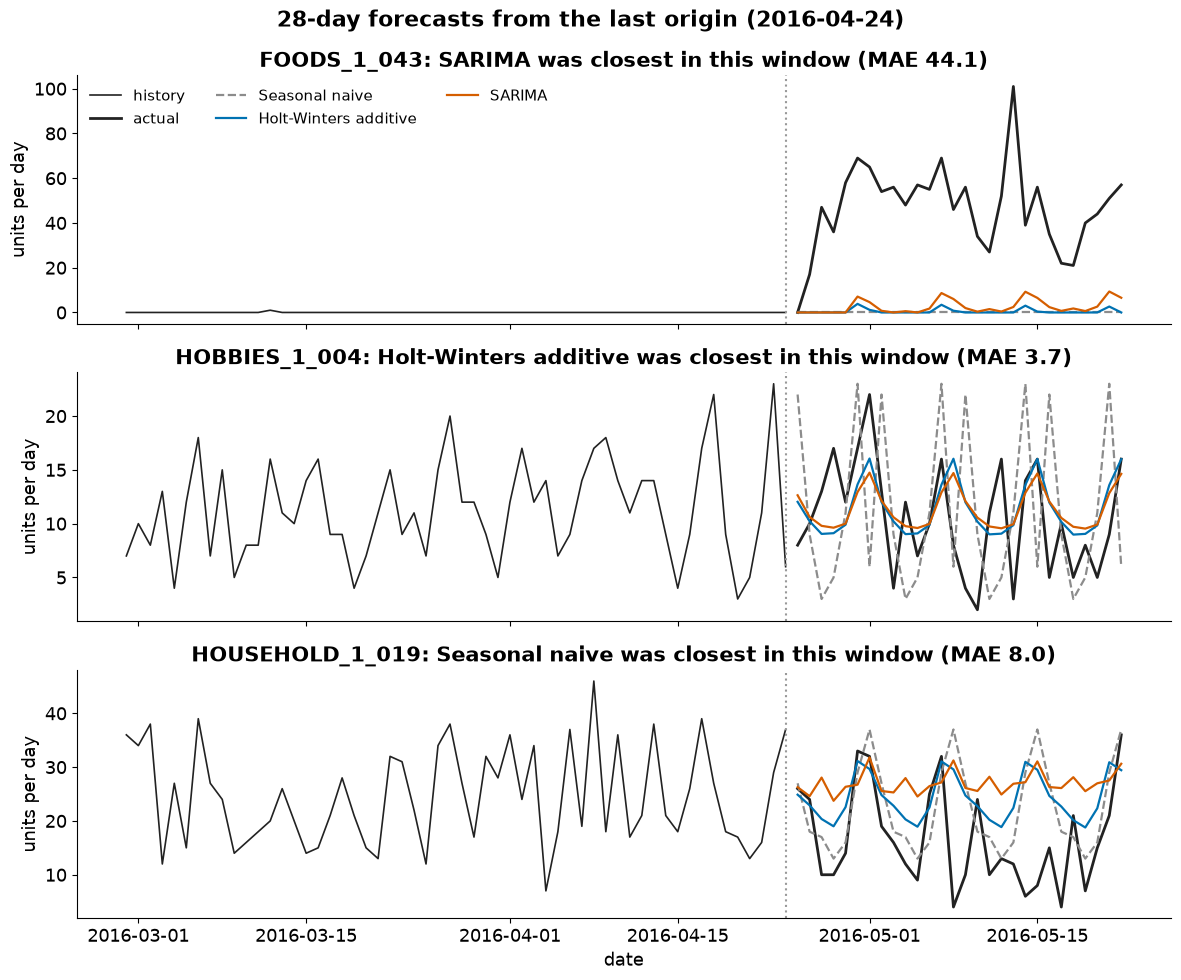

In [12]:
ex = sample.groupby("category")["item_id"].first().tolist()
last = EVAL_ORIGINS[-1]
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
for ax, item in zip(axes, ex):
    g = fc[(fc["item_id"] == item) & (fc["origin"] == last)]
    hist = long_df[(long_df["item_id"] == item) & (long_df["date"] > last - pd.Timedelta(days=56)) & (long_df["date"] <= last)]
    ax.plot(hist["date"], hist["sales"], color=COLORS["actual"], lw=1.2, label="history")
    a = g[g["model"] == "sarima"]
    ax.plot(a["date"], a["actual"], color=COLORS["actual"], lw=2, label="actual")
    for mdl in ["seasonal_naive", "hw_add", "sarima"]:
        x = g[g["model"] == mdl]
        ax.plot(x["date"], x["forecast"], color=COLORS[mdl], lw=1.6, ls="--" if mdl == "seasonal_naive" else "-", label=NAMES[mdl])
    ax.axvline(last, color="#999999", ls=":")
    err = {mdl: np.mean(np.abs(x["actual"] - x["forecast"])) for mdl, x in g.groupby("model") if mdl in ["seasonal_naive", "hw_add", "sarima"]}
    closest = min(err, key=err.get)
    ax.set_title(f"{item}: {NAMES[closest]} was closest in this window (MAE {err[closest]:.1f})")
    ax.set_ylabel("units per day")
axes[-1].set_xlabel("date")
axes[0].legend(ncol=3, loc="upper left", frameon=False)
fig.suptitle(f"28-day forecasts from the last origin ({last.date()})", fontsize=16, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGS / "classical_forecast_examples.png")
written.append(FIGS / "classical_forecast_examples.png")
plt.show()

## Checks

In [13]:
# 1. no lookahead: every forecast date is after its origin, and fits only see data up to the origin
#    (tests/test_classical_methods.py replaces everything after an origin with noise and checks nothing changes)
assert (fc["date"] > fc["origin"]).all() and (fc["date"] <= fc["origin"] + pd.Timedelta(days=HORIZON)).all()
# 2. every product has every model at every origin
assert fc.groupby(["item_id", "model", "origin"]).size().eq(HORIZON).all()
assert per_item.groupby("model")["item_id"].nunique().eq(150).all()

stats_rows = []
for mdl in ["hw_add", "hw_mul", "arima", "sarima"]:
    for level, mask in [("item", ~new_fc["item_id"].str.startswith("_agg_")), ("aggregate", new_fc["item_id"].str.startswith("_agg_"))]:
        x = new_fc[mask & (new_fc["model"] == mdl)].drop_duplicates(["item_id", "origin"])
        stats_rows.append({"model": mdl, "level": level, "fits": len(x), "fallback_rate": x["fallback"].mean(),
                           "not_converged_rate": (~x["converged"] & ~x["fallback"]).mean()})
run_stats = pd.DataFrame(stats_rows)
run_stats.to_csv(TABLES / "classical_run_stats.csv", index=False)
written.append(TABLES / "classical_run_stats.csv")
print(run_stats.round(4).to_string(index=False))
print("order searches where every fit failed:", int(orders["grid_failed"].sum()))

 model     level  fits  fallback_rate  not_converged_rate
hw_add      item  1050         0.0000              0.0000
hw_add aggregate    28         0.0000              0.0000
hw_mul      item  1050         0.0000              0.1419
hw_mul aggregate    28         0.0000              0.0357
 arima      item  1050         0.0000              0.0505
 arima aggregate    28         0.0000              1.0000
sarima      item  1050         0.0000              0.2990
sarima aggregate    28         0.1786              0.6786
order searches where every fit failed: 0


In [14]:
# a fit can also go wrong quietly: a forecast that is all zero after clipping, or far above anything ever sold
peak = {i: g["sales"].max() for i, g in long_df.groupby("item_id")}
peak.update({f"_agg_{k}": v.max() for k, v in totals.items()})
w = new_fc.groupby(["item_id", "origin", "model"])["forecast"].max().rename("fc_max").reset_index()
w["level"] = np.where(w["item_id"].str.startswith("_agg_"), "aggregate", "item")
w["all_zero"] = w["fc_max"] == 0
w["above_3x_peak"] = w["fc_max"] > 3 * w["item_id"].map(peak)
degenerate = w.groupby(["level", "model"]).agg(windows=("fc_max", "size"), all_zero=("all_zero", "sum"),
                                              above_3x_peak=("above_3x_peak", "sum")).reset_index()
degenerate.to_csv(TABLES / "classical_degenerate.csv", index=False)
written.append(TABLES / "classical_degenerate.csv")
print(degenerate.to_string(index=False))
print("\nthe broken windows on the totals:")
print(w[(w["level"] == "aggregate") & (w["all_zero"] | w["above_3x_peak"])].to_string(index=False))

    level  model  windows  all_zero  above_3x_peak
aggregate  arima       28         0              0
aggregate hw_add       28         0              0
aggregate hw_mul       28         0              0
aggregate sarima       28         4              1
     item  arima     1050         2              0
     item hw_add     1050         1              0
     item hw_mul     1050         8              0
     item sarima     1050         1              0

the broken windows on the totals:
       item_id     origin  model        fc_max     level  all_zero  above_3x_peak
 _agg_CA_TOTAL 2015-11-08 sarima 306915.745603 aggregate     False           True
    _agg_FOODS 2015-11-08 sarima      0.000000 aggregate      True          False
    _agg_FOODS 2015-12-06 sarima      0.000000 aggregate      True          False
  _agg_HOBBIES 2015-11-08 sarima      0.000000 aggregate      True          False
_agg_HOUSEHOLD 2015-11-08 sarima      0.000000 aggregate      True          False


## What we found

On all 726 products, ETS has a median MASE of 0.755 against 0.976 for seasonal naive, so smoothing the level and
the weekly pattern cuts the typical error by about a quarter. A MASE below 1 means beating "repeat last week" as it
does inside the training data; seasonal naive itself sits just under 1 because it forecasts 28 days ahead from a
single week.

On the 150-product sample the classical models line up like this (median MASE): SARIMA 0.755, ETS 0.756,
Holt-Winters additive 0.757, Holt-Winters multiplicative 0.761, ARIMA 0.794 and seasonal naive 0.973. RMSE, MAE and
WAPE put them in the same order. SARIMA beats seasonal naive by 0.223 (95% CI 0.200 to 0.237) and Holt-Winters by
0.218 (0.207 to 0.233), both clearly significant, and both win on about 97% of products. MAPE has to skip the 5.4%
of days with no sales, which is one reason we lean on MASE.

How each model suits this data:

Seasonal naive copies the weekly shape perfectly but also copies last week's noise and any one-off spike, so it is
the floor every model has to clear. ETS and Holt-Winters suit these products well: the level moves slowly and the
weekly pattern is fairly stable, which is exactly what they model. The damping in ETS stops a short-term trend from
running on for 28 days; without it Holt-Winters is almost as good, so the trend hardly matters here. ARIMA does not
suit the data: it has no weekly term, and that costs it 0.04 in MASE. SARIMA adds the weekly terms back and is the
best classical model by a hair. Multiplicative Holt-Winters is not better than additive on these products, not even
on the ones with more zero days (0.762 against 0.763), probably because they are busy sellers with only about 6%
zero days, so the +1 trick barely matters. TSB, built for products that sell now and then, did worse than plain
ETS on the 26 intermittent products (0.986 against 0.962): even those sell often enough for ordinary smoothing.

The totals were where things went wrong. SARIMA fitted on the FOODS total has a MASE of 1.976, far worse than
seasonal naive, because some fits diverged without raising an error: five windows on the totals came out all zero
or far above anything the total ever sold. On single products this almost never happened (1 to 8 broken windows
out of 1,050 per model). 07b shows it is a numbers problem. No product-level fit had to fall back to seasonal naive.

## What comes next

`07b_classical_residuals` checks what these models leave behind in their residuals.

In [15]:
# files this notebook wrote
for p in written:
    print(p.relative_to(ROOT), f"{p.stat().st_size / 1e3:,.0f} KB")

data\processed\breaks_by_origin.csv 424 KB
outputs\tables\classical_sample_items.csv 4 KB
data\processed\local_static_forecasts.parquet 938 KB
outputs\tables\classical_726_scores.csv 222 KB
outputs\tables\classical_orders.csv 16 KB
outputs\tables\classical_forecasts.parquet 1,406 KB
outputs\tables\classical_metrics_item_origin.csv 1,069 KB
outputs\tables\classical_metrics_summary.csv 7 KB
outputs\tables\classical_h4.csv 1 KB
outputs\figures\classical_forecast_examples.png 320 KB
outputs\tables\classical_run_stats.csv 0 KB
outputs\tables\classical_degenerate.csv 0 KB
